# Defining final dataframe to use


---

## The pipeline

`Data_Exploration.ipynb` is where the problems were found; this notebook is where they get
fixed, and the result is written to **`clean_data/`** — the only data modelling should read.

The exploration notebook deliberately keeps reading the *raw* bouts file, glitches and all,
so that the diagnostics that found the problem (`mp4_fish_5_impossible.mp4`, the red ▾
markers in the distance panels, `worst_jumps`) keep working and keep documenting it.

Three steps here, each one traceable to a measured finding:

| # | fix | because |
|---|---|---|
| 1 | repair tracking excursions in the per-frame positions | 558 frames dataset-wide leap and return at 100–1900 mm/s; two of them became bouts with impossible speeds (fish 5, `pause 32`) |
| 2 | re-segment from the repaired trajectory | the displacement gate structurally cannot catch them — it compares window *endpoints*, and the smoothing blunts spikes that land on one |
| 3 | flag, do not delete, the quiescence rows | on a >10 s gap row `distance` and `Δθ` describe the gap, not a bout — but the gap itself is real behaviour worth modelling |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
# Prefer the copy beside this notebook, so Data_Preprocess/ + data/ is self-contained;
# fall back to the repo's scripts/. Both must stay in sync -- SB.__file__ is printed below
# so a run always records which one it actually used.
_sb_dir = next((p for p in (Path.cwd(), ROOT / "Data_Preprocess", ROOT / "scripts")
                if (p / "segment_bouts.py").exists()), None)
if _sb_dir is None:
    raise FileNotFoundError("segment_bouts.py not found beside this notebook or in scripts/")
sys.path.insert(0, str(_sb_dir))
import segment_bouts as SB          # the canonical segmentation -- not re-implemented here

IN_DIR = ROOT / "data" / "data" / "df_transformed"
ROI_PHYS = ROOT / "data" / "data" / "Original_data" / "ROIdef2025-02-20T12_09_16.csv"
OUT_DIR = ROOT / "clean_data"
OUT_DIR.mkdir(exist_ok=True)

PX_PER_MM_PHYS = 3.60               # physical scale from the raw ROIdef (100 mm dish)
FPS = SB.FPS
QUIET_S = 10.0                      # a "no-bout stretch" starts here (Data_Exploration §8)

csvs = sorted(IN_DIR.glob("*_transformed_abs.csv"))
print(f"ROOT     : {ROOT}")
print(f"per-fish : {len(csvs)} files")
print(f"output   : {OUT_DIR}")
print(f"gate     : {SB.DISP_MIN_PX:.2f} .. {SB.DISP_MAX_PX:.2f} px "
      f"({SB.DISP_MIN_MM} .. {SB.DISP_MAX_MM} mm), window +/- {SB.DISP_WIN_FR} frames")
print(f"segmenter: {SB.__file__}")

ROOT     : C:\Users\arthu\mp_semiCL_behavior
per-fish : 15 files
output   : C:\Users\arthu\mp_semiCL_behavior\clean_data
gate     : 1.10 .. 91.75 px (0.3 .. 25.0 mm), window +/- 15 frames
segmenter: C:\Users\arthu\mp_semiCL_behavior\Data_Preprocess\segment_bouts.py


### Step 1 — repair tracking erros

Occasionally, tracking of the fish is lost, where the fish is lost for a frame or two and is reported to be in an elsewhere position (generally dish edge), creating very high speed bouts because of the Gaussian smoothing. 

So: a step over `JUMP_PX` opens an excursion, and it closes at the first frame back within
`JUMP_PX` of the position just before the jump. Only runs no longer than `MAX_RUN` frames
are repaired — a leap that never returns is the fish actually going somewhere.

`JUMP_PX` is 12 px = **100 mm/s** in a single frame. For scale, a larval zebrafish burst
peaks near 50 mm/s, the 99.9th percentile of real per-frame speed is 48 mm/s, and the
glitches sit at 200–1900 mm/s — so the threshold sits in a wide empty gap, not on a
distribution's shoulder.

This runs before gaussian smoothing, detecting what the smoothing misses.

In [2]:
JUMP_PX = 100.0 * PX_PER_MM_PHYS / FPS      # 12 px/frame = 100 mm/s
MAX_RUN = 5                                  # longest excursion treated as a tracking loss


def find_excursions(x, y, jump_px=JUMP_PX, max_run=MAX_RUN):
    """Boolean mask of frames where the tracker left and came back.

    Generalises the single-frame '45 -> 200 -> 46' case to short runs. Returns a mask over
    the same index as x/y; frames outside any excursion are untouched.
    """
    n = len(x)
    step = np.r_[0.0, np.hypot(np.diff(x), np.diff(y))]
    bad = np.zeros(n, bool)
    i = 1
    while i < n:
        if step[i] > jump_px:
            hx, hy = x[i - 1], y[i - 1]                 # where it was before the leap
            j, stop = i, min(i + max_run + 1, n)
            while j < stop and np.hypot(x[j] - hx, y[j] - hy) > jump_px:
                j += 1
            if j < stop:                                # came back -> tracking loss
                bad[i:j] = True
                i = j
                continue
        i += 1
    return bad


def repair(x, y, mask):
    """Linear interpolation across the flagged frames (runs are 1-5 frames, so this is
    a short bridge between two trusted positions rather than an invention)."""
    xs, ys = x.astype(float).copy(), y.astype(float).copy()
    xs[mask], ys[mask] = np.nan, np.nan
    xs = pd.Series(xs).interpolate(limit_direction="both").to_numpy()
    ys = pd.Series(ys).interpolate(limit_direction="both").to_numpy()
    return xs, ys


report, frames_out, repaired_rows = [], [], []
for path in csvs:
    fid = int(path.stem.split("_f")[-1].split("_")[0])
    df = pd.read_csv(path)
    px, py = f"f{fid}_x", f"f{fid}_y"
    ok = df[px].notna() & df[py].notna()
    x = df.loc[ok, px].to_numpy(float)
    y = df.loc[ok, py].to_numpy(float)
    bad = find_excursions(x, y)
    s0 = np.r_[0.0, np.hypot(np.diff(x), np.diff(y))]
    xs, ys = repair(x, y, bad)
    s1 = np.r_[0.0, np.hypot(np.diff(xs), np.diff(ys))]
    df.loc[ok, px], df.loc[ok, py] = xs, ys
    frames_out.append((fid, df))
    fr = df.loc[ok, "frame"].to_numpy()[bad]
    report.append(dict(fish=fid, frames=len(x), repaired=int(bad.sum()),
                       pct=round(100 * bad.mean(), 4),
                       max_step_before=round(float(s0.max()), 1),
                       max_step_after=round(float(s1.max()), 1),
                       over_100mm_s_before=int((s0 > JUMP_PX).sum()),
                       over_100mm_s_after=int((s1 > JUMP_PX).sum())))
    if len(fr):
        repaired_rows.append(pd.DataFrame(dict(fish_id=fid, frame=fr)))

rep = pd.DataFrame(report).set_index("fish")
print(rep.to_string())
print(f"\nrepaired {rep.repaired.sum()} of {rep.frames.sum():,} frames "
      f"({100*rep.repaired.sum()/rep.frames.sum():.4f} %)")
# written ONCE, not appended per fish -- re-running the notebook must not duplicate rows
_rf = (pd.concat(repaired_rows, ignore_index=True) if repaired_rows
       else pd.DataFrame(columns=["fish_id", "frame"]))
_rf.to_csv(OUT_DIR / "repaired_frames.csv", index=False)
print(f"frame list -> {OUT_DIR / 'repaired_frames.csv'}  ({len(_rf)} rows)")

      frames  repaired     pct  max_step_before  max_step_after  over_100mm_s_before  over_100mm_s_after
fish                                                                                                    
0     313355         0  0.0000             28.6            28.6                   20                  20
10    313380        18  0.0057             43.0            43.0                   47                  30
11    313380        11  0.0035             91.2            27.5                   27                  17
12    313380         0  0.0000             28.3            28.3                   28                  28
13    313380         7  0.0022             56.7            56.7                   47                  40
14    313319        11  0.0035             34.5            34.5                   41                  37
1     313380         3  0.0010             29.4            29.4                   45                  43
2     313380         8  0.0026             27.8        

### Step 2 — re-segment from the repaired trajectory

We apply discretization scheme same as is, after having applied step 1 correction.

In [3]:
recs = []
for fid, df in frames_out:
    prefix = SB.fish_prefix(df)
    recs += SB.segment_fish(df, prefix, fid, speed_thresh_k=1.0, onset_mode="trough")
bouts = pd.DataFrame(recs)
bouts = SB.flag_near_wall(bouts)
bouts = SB.add_dist_to_border(bouts, SB.load_physical_dish(ROI_PHYS))
bouts = SB.add_dist_to_dot(bouts, transformed_dir=IN_DIR)
print(f"{len(bouts):,} bouts, {bouts.fish_id.nunique()} fish")
print("columns:", list(bouts.columns))

71,937 bouts, 15 fish
columns: ['fish_id', 'segment_id', 'bout_index', 'frame_onset', 't_onset_s', 'dtheta_rad', 'dtheta_deg', 'dtheta_ori_deg', 'dt_s', 'distance_px', 'distance_nominal_mm', 'heading_rad', 'f_ori_rad', 'x_px', 'y_px', 'stimulus', 'stim_angle_rad', 'n_dots_left', 'n_dots_right', 'speed_left', 'speed_right', 'side', 'moving', 'bout_type', 'near_wall', 'dist_to_border_px', 'dist_to_border_norm', 'dot_cx', 'dot_cy', 'dot_dist_px', 'dot_prox']


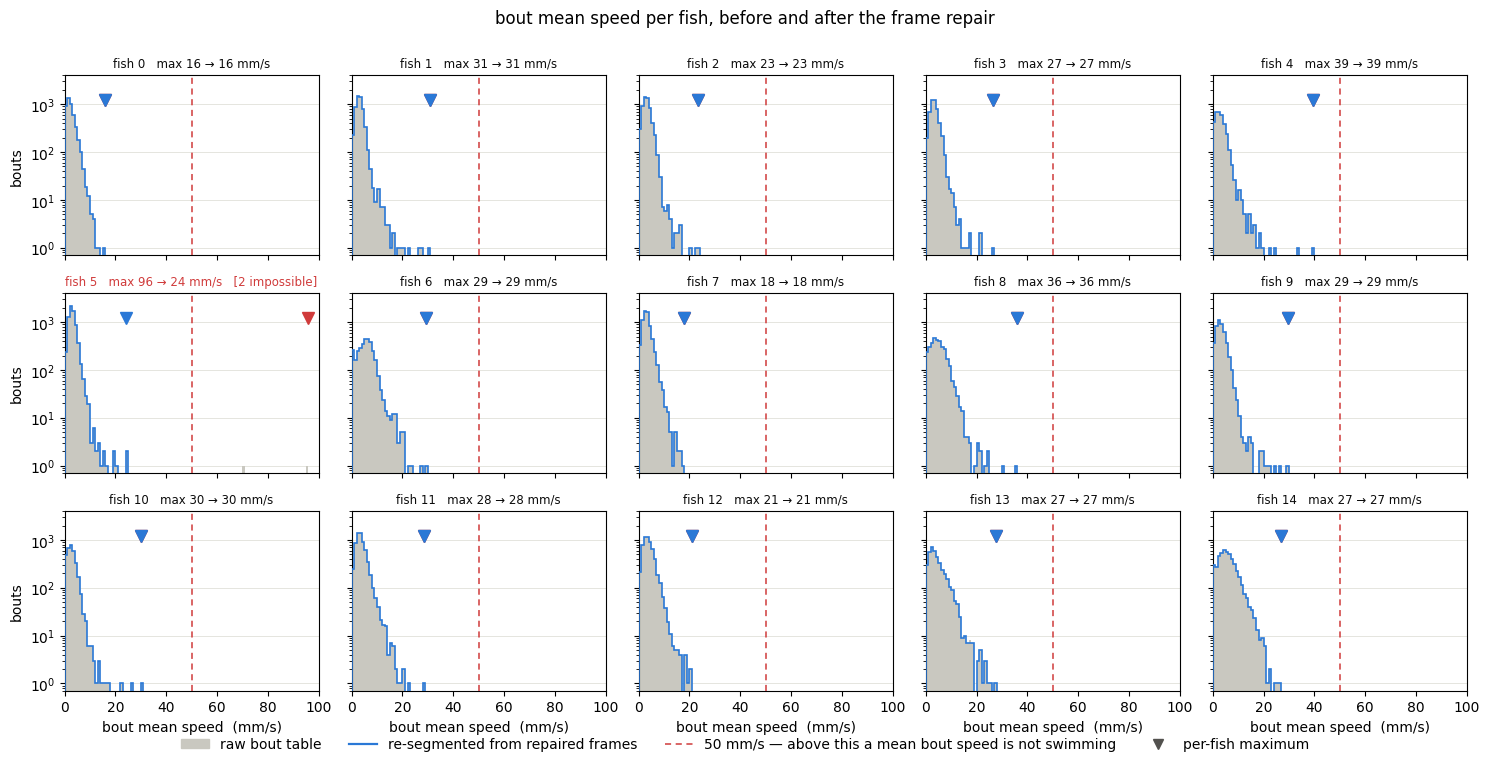

bouts over 50 mm/s   raw 2  ->  clean 0
fastest bout      raw 95.8 mm/s  ->  clean 39.4 mm/s
longest bout      raw 218.5 px  ->  clean 195.6 px

the raw rows that could not be real, and are now gone:
 fish_id  bout_index  frame_onset  dt_s  distance_px  v_mm_s
       5        2165       105639  0.80       203.66   70.71
       5        2166       105663  0.63       218.49   95.83


In [4]:
# Did the repair actually remove them? Same per-fish distribution view as
# Data_Exploration §13, on the axis that DEFINES "impossible": a bout's mean speed.
# Grey fill = raw bout table, blue outline = re-segmented from the repaired frames.
# The v marker is that fish's maximum, in each colour.
import matplotlib.pyplot as plt

V_MAX = 50.0                      # mm/s -- 99.9th pct of real per-frame speed is 48
RAW = pd.read_csv(ROOT / "data" / "bouts_GsizeMotionSingle.csv")
for _d in (RAW, bouts):
    _d["v_mm_s"] = _d["distance_px"] / PX_PER_MM_PHYS / _d["dt_s"]

fish = sorted(bouts["fish_id"].unique())
edges = np.linspace(0, 100, 101)
top = 4.0e3
fig, axes = plt.subplots(3, 5, figsize=(15, 7.4), sharex=True, sharey=True)
for ax, f in zip(axes.ravel(), fish):
    r = RAW.loc[RAW["fish_id"] == f, "v_mm_s"].dropna().to_numpy(float)
    c = bouts.loc[bouts["fish_id"] == f, "v_mm_s"].dropna().to_numpy(float)
    ax.hist(r, bins=edges, color="#c9c8c0", log=True, zorder=2)
    ax.hist(c, bins=edges, histtype="step", color="#2a78d6", lw=1.2, log=True, zorder=3)
    ax.axvline(V_MAX, color="#d03b3b", lw=1.1, ls=(0, (4, 3)), zorder=4)
    ax.plot([r.max()], [top * .30], "v", color="#d03b3b", ms=8, zorder=5)
    ax.plot([c.max()], [top * .30], "v", color="#2a78d6", ms=8, zorder=5)
    n_bad = int((r > V_MAX).sum())
    ax.set_title(f"fish {f}   max {r.max():.0f} → {c.max():.0f} mm/s"
                 + (f"   [{n_bad} impossible]" if n_bad else ""),
                 fontsize=8.5, color="#d03b3b" if n_bad else "#0b0b0b")
    ax.set_ylim(.7, top)
    ax.set_xlim(0, 100)
    ax.grid(axis="y", color="#e1e0d9", lw=.6, zorder=0)
    ax.set_axisbelow(True)
for ax in axes[-1]:
    ax.set_xlabel("bout mean speed  (mm/s)")
for ax in axes[:, 0]:
    ax.set_ylabel("bouts")
fig.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color="#c9c8c0", label="raw bout table"),
    plt.Line2D([], [], color="#2a78d6", lw=1.6, label="re-segmented from repaired frames"),
    plt.Line2D([], [], color="#d03b3b", lw=1.1, ls=(0, (4, 3)),
               label=f"{V_MAX:.0f} mm/s — above this a mean bout speed is not swimming"),
    plt.Line2D([], [], marker="v", color="#52514e", ls="none", ms=7, label="per-fish maximum")],
    loc="lower center", ncol=4, bbox_to_anchor=(.5, -.02), frameon=False)
fig.suptitle("bout mean speed per fish, before and after the frame repair", y=1.0)
fig.tight_layout()
plt.show()

hi = RAW[RAW["v_mm_s"] > V_MAX]
print(f"bouts over {V_MAX:.0f} mm/s   raw {len(hi)}  ->  clean {int((bouts.v_mm_s > V_MAX).sum())}")
print(f"fastest bout      raw {RAW.v_mm_s.max():.1f} mm/s  ->  clean {bouts.v_mm_s.max():.1f} mm/s")
print(f"longest bout      raw {RAW.distance_px.max():.1f} px  ->  clean {bouts.distance_px.max():.1f} px")
print("\nthe raw rows that could not be real, and are now gone:")
print(hi[["fish_id", "bout_index", "frame_onset", "dt_s", "distance_px", "v_mm_s"]]
      .round(2).to_string(index=False))

### Step 3 — dealing with the "dead" periods

On a bout whose `dt_s` exceeds 10 s, `distance_px` and `dtheta_deg` are measured onset to
onset *across the gap*: implied speed 0.86 px/s against 11.9, and |Δθ| near-uniform. They are
not bout kinematics and must not be fitted as such.

* `gap_after` — this row's `dt_s`, `distance_px`, `dtheta_deg` describe a quiescent gap
* `active` — safe for per-bout kinematics (neither this leg nor the previous one spans a gap)

In [5]:
bouts = bouts.sort_values(["fish_id", "bout_index"]).reset_index(drop=True)
bouts["gap_after"] = bouts["dt_s"] > QUIET_S
bouts["gap_before"] = bouts.groupby("fish_id")["gap_after"].shift(1).fillna(False)
bouts["active"] = ~(bouts["gap_after"] | bouts["gap_before"])

n = len(bouts)
print(f"gap_after  {bouts.gap_after.sum():6,} rows ({100*bouts.gap_after.mean():.2f} %) "
      f"carrying {100*bouts.loc[bouts.gap_after,'dt_s'].sum()/bouts.dt_s.sum():.1f} % of the time")
print(f"active     {bouts.active.sum():6,} rows ({100*bouts.active.mean():.2f} %)")
print("\nno fish is excluded -- coverage varies instead:")
print(bouts.groupby("fish_id").agg(bouts=("active", "size"),
                                   active=("active", "sum"),
                                   pct_active=("active", lambda s: round(100*s.mean(), 1))).to_string())

gap_after   1,284 rows (1.78 %) carrying 29.5 % of the time
active     69,572 rows (96.71 %)

no fish is excluded -- coverage varies instead:
         bouts  active  pct_active
fish_id                           
0         4620    4530        98.1
1         5366    5257        98.0
2         5639    5522        97.9
3         4850    4714        97.2
4         3292    3034        92.2
5         6846    6791        99.2
6         3184    2934        92.1
7         6505    6409        98.5
8         3266    3070        94.0
9         4648    4471        96.2
10        3160    2903        91.9
11        6201    6093        98.3
12        5721    5622        98.3
13        3892    3711        95.3
14        4747    4511        95.0


A single head cannot reproduce these "dead" periods, so we decide to mask them for model training, and not count them in the likelihood. This effectively also means the dt distributions won't have these really fat tails and model will not attempt to learn to produce a "dead" state.

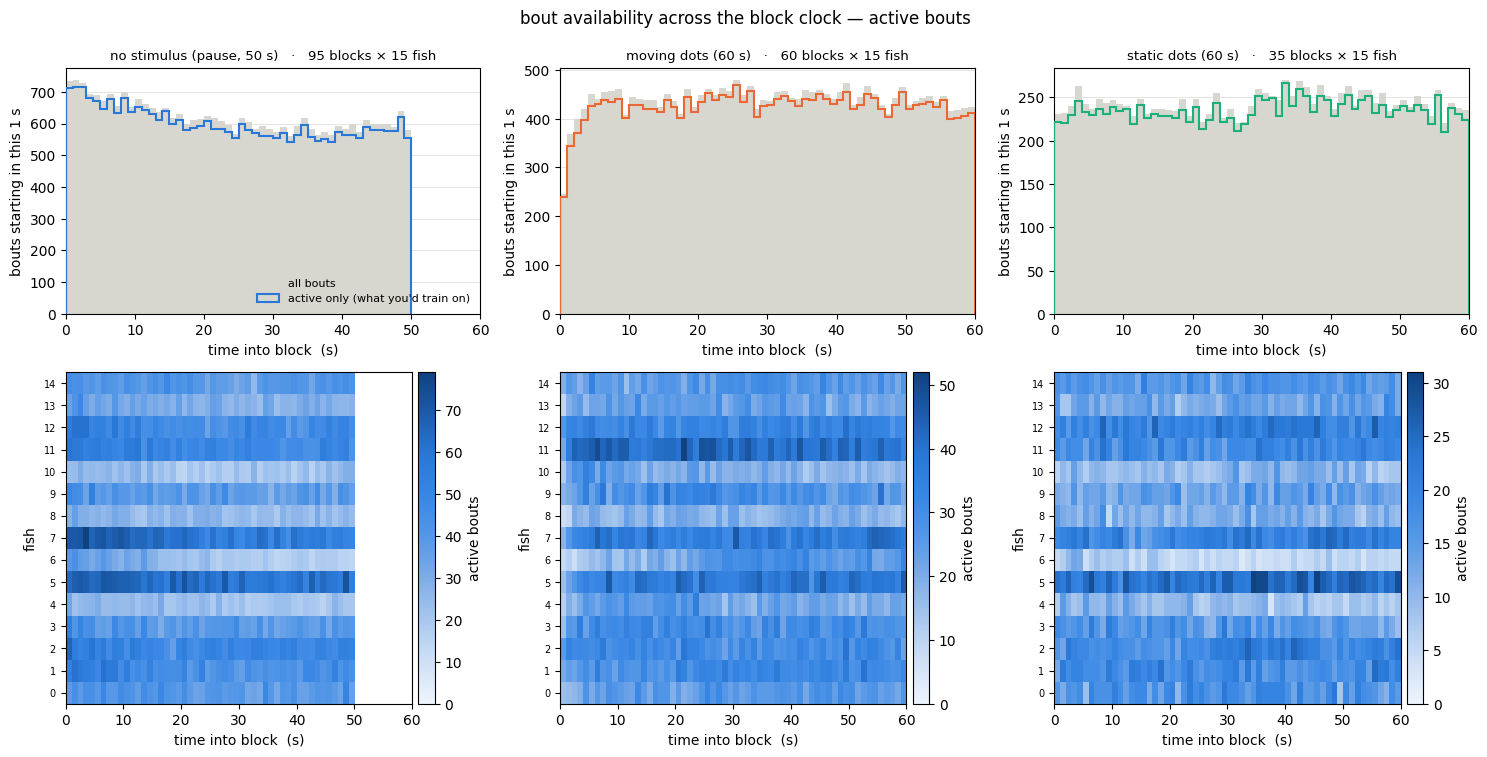

no stimulus (pause, 50 s)    30,030 bouts    542- 714 per 1 s pooled   empty seconds 0   worst single fish  14/s
moving dots (60 s)           25,456 bouts    239- 468 per 1 s pooled   empty seconds 0   worst single fish   7/s
static dots (60 s)           14,086 bouts    210- 266 per 1 s pooled   empty seconds 0   worst single fish   2/s


In [6]:
# Does masking the gap rows leave HOLES in the block clock? A model conditioned on
# time-into-block needs every phase populated. Grey = all bouts, colour = active only;
# the heatmaps repeat it per fish so one quiet animal cannot be averaged away.
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SEQ = ["#eef4fc", "#cfe0f6", "#a9c8ef", "#7fade8", "#5598e7",
       "#3987e5", "#2a78d6", "#1c5cab", "#104281"]
CYCLE_FR, PAUSE_FR = 3300, 1500          # 110 s cycle: 50 s pause + 60 s stimulus

_pos = bouts["frame_onset"] % CYCLE_FR
_in_stim = _pos >= PAUSE_FR
bouts["blk"] = bouts["frame_onset"] // CYCLE_FR * 2 + _in_stim.astype(int)
bouts["t_blk"] = np.where(_in_stim, _pos - PAUSE_FR, _pos) / FPS
_st = bouts["stimulus"].astype(str).str.startswith("CLsemi")
bouts["cond"] = np.where(~_st, "none",
                np.where(bouts["moving"].astype(bool), "moving", "static"))

CONDS = {"none": ("no stimulus (pause, 50 s)", BLUE, 50),
         "moving": ("moving dots (60 s)", ORANGE, 60),
         "static": ("static dots (60 s)", AQUA, 60)}
FISH = sorted(bouts["fish_id"].unique())
cmap = LinearSegmentedColormap.from_list("seq", SEQ)

fig, axes = plt.subplots(2, 3, figsize=(15, 7.6), gridspec_kw=dict(height_ratios=[1, 1.35]))
for j, (c, (lab, col, dur)) in enumerate(CONDS.items()):
    g = bouts[bouts["cond"] == c]
    edges = np.arange(0, dur + 1, 1.0)
    ax = axes[0, j]
    ax.hist(g["t_blk"], bins=edges, color="#d8d7cf", label="all bouts", zorder=2)
    ax.hist(g.loc[g["active"], "t_blk"], bins=edges, histtype="step", color=col, lw=1.5,
            label="active only (what you'd train on)", zorder=3)
    ax.set_title(f"{lab}   ·   {g['blk'].nunique()} blocks × {len(FISH)} fish", fontsize=9.5)
    ax.set_xlabel("time into block  (s)")
    ax.set_ylabel("bouts starting in this 1 s")
    ax.set_xlim(0, 60)
    ax.set_ylim(0)
    ax.grid(axis="y", color="#e1e0d9", lw=.6, zorder=0)
    ax.set_axisbelow(True)
    if j == 0:
        ax.legend(loc="lower right", fontsize=8, frameon=False)

    ga = g[g["active"]]
    M = np.vstack([np.histogram(ga.loc[ga["fish_id"] == f, "t_blk"], bins=edges)[0]
                   for f in FISH])
    ax = axes[1, j]
    im = ax.imshow(M, aspect="auto", origin="lower", cmap=cmap, vmin=0,
                   extent=(0, dur, -.5, len(FISH) - .5))
    ax.set_yticks(range(len(FISH)))
    ax.set_yticklabels([str(f) for f in FISH], fontsize=7)
    ax.set_ylabel("fish")
    ax.set_xlabel("time into block  (s)")
    ax.set_xlim(0, 60)
    plt.colorbar(im, ax=ax, pad=.015, label="active bouts")
fig.suptitle("bout availability across the block clock — active bouts", y=.99)
fig.tight_layout()
plt.show()

for c, (lab, _, dur) in CONDS.items():
    g = bouts[(bouts["cond"] == c) & bouts["active"]]
    h = np.histogram(g["t_blk"], bins=np.arange(0, dur + 1, 1.0))[0]
    worst = min(np.histogram(g.loc[g["fish_id"] == f, "t_blk"],
                             bins=np.arange(0, dur + 1, 1.0))[0].min() for f in FISH)
    print(f"{lab:<28}{len(g):>7,} bouts   {h.min():>4}-{h.max():>4} per 1 s pooled"
          f"   empty seconds {int((h == 0).sum())}   worst single fish {worst:>3}/s")

### Step 3b — modelling features

The columns a bout-to-bout model needs that the segmenter does not produce. Four decisions
are baked in here rather than left to the training script, so they cannot drift:

**Two block clocks, not one.** A pause block is 50 s and a stimulus block 60 s, so a single
0–1 phase feature would map different real durations onto the same number. `t_pause_norm`
and `t_stim_norm` each run 0→1 over their own block and sit at 0 during the other, so the
model never has to infer which clock it is reading. `t_blk` keeps the raw seconds.

**`run_id`, because `segment_id` cannot do this job.** It has a single value for the whole
session — no fish has a tracking break after frame 0 — so it is not a sequence boundary. A
*run* is a maximal stretch of bouts uninterrupted by a >10 s gap. This matters because
dropping the gap rows leaves holes, and an autoregressive head that closes over one learns
that the bout before a five-minute freeze is normally followed by the bout after it.

A useful property: a `gap_before` row always *starts* a run and a `gap_after` row always
*ends* one, so every inactive row sits at a run edge. Filtering on `active` therefore leaves
each run contiguous — you never punch a hole in the middle of a sequence.

**Lags shift within `run_id`, never within `fish_id`.** Otherwise the first bout after every
gap inherits the last bout from before it, which is the error the mask exists to prevent.

**`dots_on` gates the stimulus head.** `stim_angle_rad` and `dot_dist_px` are NaN on pause
bouts by definition — there are no dots to bear toward. Do not impute 0: an angle of 0 means
*dead ahead*, which is the opposite of *absent*.

⚠ `crosses_block` flags the 2.7 % of active bouts whose interval runs past the end of their
block. On those, `cond` and `stim_angle_rad` describe the stimulus at **onset** while `dt`,
`distance` and `Δθ` cover an interval during which the dots changed or switched off. Same
class of error as the gap rows, an order of magnitude smaller — flagged, not dropped, so it
can be tested rather than assumed harmless.

In [7]:
CYCLE_FR, PAUSE_FR, STIM_FR = 3300, 1500, 1800     # 110 s: 50 s pause + 60 s stimulus

_pos = bouts["frame_onset"] % CYCLE_FR
_in_stim = _pos >= PAUSE_FR

# --- block clock ----------------------------------------------------------------
bouts["blk"] = bouts["frame_onset"] // CYCLE_FR * 2 + _in_stim.astype(int)
bouts["t_blk"] = np.where(_in_stim, _pos - PAUSE_FR, _pos) / FPS
bouts["t_pause_norm"] = np.where(_in_stim, 0.0, _pos / PAUSE_FR)
bouts["t_stim_norm"] = np.where(_in_stim, (_pos - PAUSE_FR) / STIM_FR, 0.0)

# --- stimulus type, and the gate for the stimulus head --------------------------
_st = bouts["stimulus"].astype(str).str.startswith("CLsemi")
bouts["cond"] = np.where(~_st, "none",
                np.where(bouts["moving"].astype(bool), "moving", "static"))
bouts["dots_on"] = _st.to_numpy()

# --- radial position, the form every analysis uses (0 = centre, 1 = wall) -------
bouts["r_norm"] = 1.0 - bouts["dist_to_border_norm"]

# --- sequence boundaries --------------------------------------------------------
bouts["run_id"] = (bouts["gap_before"]
                   | (bouts["fish_id"] != bouts["fish_id"].shift())).cumsum()
bouts["run_n_active"] = bouts["run_id"].map(
    bouts.groupby("run_id")["active"].sum()).astype(int)
# Position within the run. K-independent, and the quantity a lag-validity channel derives
# from: slot k-1 of the turn history is padded exactly when run_pos < k, so `run_pos` is a
# sufficient statistic for the whole K-column mask (the slots fill in order).
bouts["run_pos"] = bouts.groupby("run_id").cumcount()

# --- lags, WITHIN a run ---------------------------------------------------------
_g = bouts.groupby("run_id")
for _c in ("dtheta_deg", "dt_s", "distance_px"):
    bouts[f"{_c}_prev"] = _g[_c].shift(1)

# --- egocentric geometry IN THE CHORD FRAME -------------------------------------
# `stim_angle_rad` from the segmenter is referenced to the body axis `f_ori_rad`; dtheta is
# referenced to the chord. The two sit a MEDIAN 40 deg apart (10 % of bouts by >90 deg), and
# a bout-to-bout model cannot reconstruct the body axis at rollout -- it propagates
# heading += dtheta and emits nothing that updates an orientation. Training a bearing on
# f_ori and querying it at rollout with the travel heading is errors-in-variables
# attenuation of exactly the response these channels exist to carry.
#
# theta_{t-1} comes from the ROW, not from a shift: the segmentation guarantees
# dtheta_t = wrap(theta_t - theta_{t-1}) and heading_rad[t] = theta_t, so
# theta_{t-1} = heading_rad[t] - dtheta_t exactly. Immune to run boundaries, so nothing is
# lost. This is `fit_MLP_border._travel_ref`, the reference the closed loop presents.
def _wrap(a):
    return (a + np.pi) % (2 * np.pi) - np.pi


_theta_prev = _wrap(bouts["heading_rad"] - np.radians(bouts["dtheta_deg"]))
bouts["stim_angle_travel"] = _wrap(
    np.arctan2(bouts["dot_cy"] - bouts["y_px"], bouts["dot_cx"] - bouts["x_px"]) - _theta_prev)

# --- wall block: fit_MLP_border.BORDER_COLS_RAW = (dnorm, sin_psi, cos_psi) ------
# psi is the egocentric bearing to the DISH CENTRE in the same chord frame, so
# cos(psi) = +1 means heading straight at the centre and -1 straight at the wall.
# `dist_to_border_norm` is already the dnorm channel (0 = wall, 1 = centre); distance alone
# cannot say WHICH WAY to turn, which is what the sin/cos pair adds.
_dish = SB.load_physical_dish(ROI_PHYS)
_psi = _wrap(np.arctan2(bouts["fish_id"].map(_dish["cy"]) - bouts["y_px"],
                        bouts["fish_id"].map(_dish["cx"]) - bouts["x_px"]) - _theta_prev)
bouts["wall_psi_rad"] = _psi
bouts["wall_sin_psi"] = np.sin(_psi)
bouts["wall_cos_psi"] = np.cos(_psi)

# --- the interval that outruns its own block ------------------------------------
bouts["crosses_block"] = (_pos + bouts["dt_s"] * FPS) > np.where(_in_stim, CYCLE_FR, PAUSE_FR)

NEW = ["blk", "t_blk", "t_pause_norm", "t_stim_norm", "cond", "dots_on", "r_norm",
       "run_id", "run_n_active", "run_pos", "dtheta_deg_prev", "dt_s_prev", "distance_px_prev",
       "stim_angle_travel", "wall_psi_rad", "wall_sin_psi", "wall_cos_psi",
       "crosses_block"]
print(f"{len(NEW)} feature columns added -> {bouts.shape[1]} total\n")
print(bouts[NEW].dtypes.to_string())

a = bouts[bouts["active"]]
print(f"\nruns            {bouts.run_id.nunique():,}   "
      f"median {int(a.groupby('run_id').size().median())} active bouts, "
      f"{int((a.groupby('run_id').size() >= 20).sum()):,} runs with >= 20")
# every inactive row must sit at a run edge, or filtering would split a sequence
_mid = bouts.groupby("run_id").apply(
    lambda g: (~g["active"]).to_numpy()[1:-1].any() if len(g) > 2 else False,
    include_groups=False)
print(f"runs with an inactive row in the MIDDLE: {int(_mid.sum())}  (must be 0)")
print(f"crosses_block   {int(bouts.crosses_block.sum()):,} bouts "
      f"({100*a.crosses_block.mean():.1f} % of active)")
print(f"dots_on         {int(bouts.dots_on.sum()):,} bouts; "
      f"stim_angle_rad defined on {int(bouts.loc[bouts.dots_on, 'stim_angle_rad'].notna().sum()):,} of them")
print(f"lags null       {int(bouts.dtheta_deg_prev.isna().sum()):,} "
      f"(= one per run, as expected: {bouts.run_id.nunique():,})")
_sa = bouts.loc[bouts.dots_on]
print(f"dot bearing     {int(_sa.stim_angle_travel.notna().sum()):,} of {len(_sa):,} "
      f"stimulus bouts  (row-local reference loses none)")
print(f"wall block      dnorm {bouts.dist_to_border_norm.min():.3f}-"
      f"{bouts.dist_to_border_norm.max():.3f}, "
      f"cos(psi) {bouts.wall_cos_psi.min():+.2f}..{bouts.wall_cos_psi.max():+.2f}; "
      f"heading outward (cos<0) on {100*(bouts.wall_cos_psi < 0).mean():.0f} % of bouts")
# sanity: inside the PHYSICAL 5 mm shell a real fish should turn toward the centre.
# NB `near_wall` is NOT this shell -- it flags the outer 5 mm of each fish's EMPIRICAL
# extent (median centre, 0.95-quantile radius), which is 13 % of bouts against 0.2 % for
# the physical band, so the two are not interchangeable.
_shell = bouts[bouts.active & (bouts.dist_to_border_norm < 0.10)
               & (bouts.dtheta_deg.abs() > 10)]
print(f"wall check      physical 5 mm shell ({len(_shell)} turn bouts): turns toward centre "
      f"on {100*(np.sign(_shell.dtheta_deg) == np.sign(_shell.wall_psi_rad)).mean():.0f} % "
      f"(fit_MLP_border: 71-73 %, f_ori frame)")
print(f"                near_wall flags {100*bouts.near_wall.mean():.1f} % of bouts -- "
      f"empirical dish, a much wider band than the physical 5 mm")

18 feature columns added -> 53 total

blk                    int64
t_blk                float64
t_pause_norm         float64
t_stim_norm          float64
cond                     str
dots_on                 bool
r_norm               float64
run_id                 int64
run_n_active           int64
run_pos                int64
dtheta_deg_prev      float64
dt_s_prev            float64
distance_px_prev     float64
stim_angle_travel    float64
wall_psi_rad         float64
wall_sin_psi         float64
wall_cos_psi         float64
crosses_block           bool

runs            1,298   median 20 active bouts, 506 runs with >= 20


runs with an inactive row in the MIDDLE: 0  (must be 0)
crosses_block   2,551 bouts (2.7 % of active)
dots_on         40,872 bouts; stim_angle_rad defined on 40,872 of them
lags null       1,298 (= one per run, as expected: 1,298)
dot bearing     40,872 of 40,872 stimulus bouts  (row-local reference loses none)
wall block      dnorm 0.051-1.000, cos(psi) -1.00..+1.00; heading outward (cos<0) on 60 % of bouts
wall check      physical 5 mm shell (102 turn bouts): turns toward centre on 77 % (fit_MLP_border: 71-73 %, f_ori frame)
                near_wall flags 13.1 % of bouts -- empirical dish, a much wider band than the physical 5 mm


### Step 4 — t_stim_norm, t_pause_norm

Two clock features, justified separately because they act on **different channels**.

**`t_stim_norm`** — the fish turns toward a shoal much more strongly just after it appears.
The trap is that range and bearing themselves drift with block phase (static median range goes
74 → 113 px across a block), so the raw effect could be geometry in disguise. Panel A therefore
holds the stimulus state fixed — range 40–85 px, |bearing| 45–135°, the modal configuration —
and the effect survives: **P(turn toward) 0.80 in the first 5 s against 0.70 later, 14/15 fish**.
No bearing, range, group-size or condition channel can encode this, because all of them are
matched. `dt` inside the same cell is 8/15, a coin flip.

**`t_pause_norm`** — after the dots go off the fish is briefly *more active*, relaxing over
~25 s: shorter intervals, longer steps, further out. Panel B shows all three relative to the
end of the pause. The sign tests are **14/15 (dt), 13/15 (distance), 13/15 (r/R)**, while
|Δθ| is 8/15 — nothing. This one cannot be confounded with stimulus geometry at all, since
there is no stimulus during a pause.

| feature | turn head | kinematic heads |
|---|---|---|
| `t_stim_norm` | **14/15** | 8/15 |
| `t_pause_norm` | 8/15 | **14/15 · 13/15 · 13/15** |

⚠ The magnitudes are modest — 8 % on `dt`, 6 % on `distance` — so it is the sign consistency
that makes them real, not the effect size. And the two want different encodings: the pause
effect is a gradual saturating relaxation over half the block, so a linear 0→1 ramp is a fair
basis; the stimulus effect is a sharp transient confined to the first ~5 s of 60, where a
linear ramp is a poor one. `exp(−t/τ)` with τ ≈ 3–5 s, or an added "first 5 s" indicator,
would fit that shape far more directly.

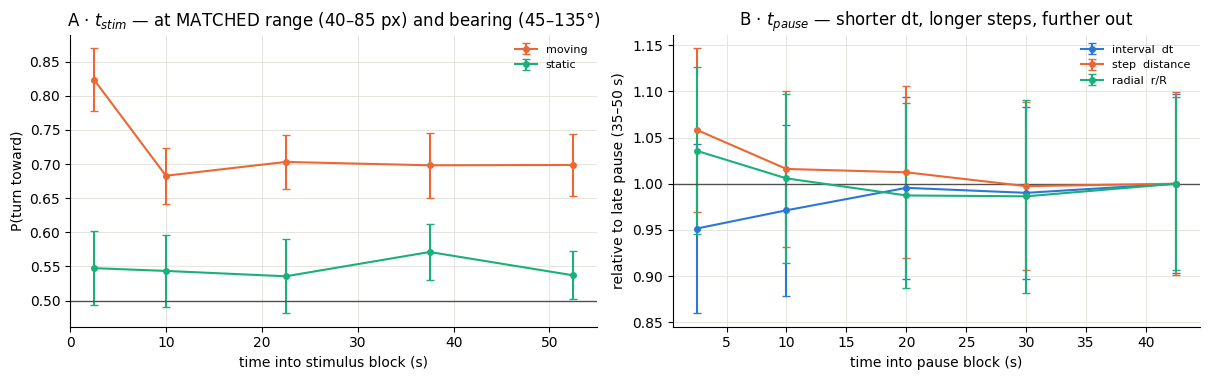

                                early     late              per fish
  t_stim  P(toward), moving      0.802    0.699        +0.103   14/15
  t_pause dt (s)                1.172    1.237        -0.064   14/15
  t_pause distance (px)        16.057   15.191        +0.865   13/15
  t_pause r/R                   0.466    0.450        +0.016   13/15
  t_pause |dtheta| (deg)       37.488   37.308         +0.180   8/15


In [8]:
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e1e0d9"
a = bouts[bouts.active].copy()
a["absphi"] = np.degrees(a.stim_angle_travel.abs())


def band(sub, col, bins, how="mean", min_n=20, min_fish=8):
    """mean +/- 95% CI ACROSS FISH of a per-fish statistic, per time bin."""
    x, m, e = [], [], []
    for lo, hi in bins:
        g = sub[sub.t_blk.between(lo, hi)]
        per = g.groupby("fish_id")[col].agg([how, "size"])
        per = per[per["size"] >= min_n][how]
        if len(per) < min_fish:
            continue
        x.append((lo + hi) / 2); m.append(per.mean())
        e.append(1.96 * per.std(ddof=1) / np.sqrt(len(per)))
    return np.array(x), np.array(m), np.array(e)


fig, ax = plt.subplots(1, 2, figsize=(12.2, 3.9))

# --- A. t_stim_norm: onset response at MATCHED range and bearing ---------------
SB_ = [(0, 5), (5, 15), (15, 30), (30, 45), (45, 60)]
cell = a[a.dots_on & a.dot_dist_px.between(40, 85) & a.absphi.between(45, 135)
         & (a.dtheta_deg.abs() > 10) & a.stim_angle_travel.notna()].copy()
cell["toward"] = (np.sign(cell.dtheta_deg) == np.sign(cell.stim_angle_travel)).astype(float)
for c, col in (("moving", ORANGE), ("static", AQUA)):
    x, m, e = band(cell[cell.cond == c], "toward", SB_)
    ax[0].errorbar(x, m, yerr=e, fmt="-o", ms=4, color=col, capsize=3, label=c)
ax[0].axhline(.5, color=INK2, lw=1)
ax[0].set_xlabel("time into stimulus block (s)")
ax[0].set_ylabel("P(turn toward)")
ax[0].set_title("A · $t_{stim}$ — at MATCHED range (40–85 px) and bearing (45–135°)")
ax[0].legend(fontsize=8, frameon=False)

# --- B. t_pause_norm: activity relaxes after the dots go off -------------------
PB = [(0, 5), (5, 15), (15, 25), (25, 35), (35, 50)]
p = a[a.cond == "none"]
for col, how, lab, colr in (("dt_s", "median", "interval  dt", BLUE),
                            ("distance_px", "median", "step  distance", ORANGE),
                            ("r_norm", "mean", "radial  r/R", AQUA)):
    x, m, e = band(p, col, PB, how=how)
    ax[1].errorbar(x, m / m[-1], yerr=e / m[-1], fmt="-o", ms=4, color=colr,
                   capsize=3, label=lab)
ax[1].axhline(1.0, color=INK2, lw=1)
ax[1].set_xlabel("time into pause block (s)")
ax[1].set_ylabel("relative to late pause (35–50 s)")
ax[1].set_title("B · $t_{pause}$ — shorter dt, longer steps, further out")
ax[1].legend(fontsize=8, frameon=False)
for a_ in ax:
    a_.grid(color=GRID, lw=.6, zorder=0); a_.set_axisbelow(True)
    a_.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

# per-fish sign tests -- the thing that makes these real rather than noise
print(f"{'':28}{'early':>9}{'late':>9}{'per fish':>22}")
e_ = cell[(cell.cond == "moving") & (cell.t_blk < 5)].groupby("fish_id").toward.mean()
l_ = cell[(cell.cond == "moving") & (cell.t_blk > 30)].groupby("fish_id").toward.mean()
dd = (e_ - l_).dropna()
print(f"  t_stim  P(toward), moving  {e_.mean():>9.3f}{l_.mean():>9.3f}"
      f"{f'{dd.mean():+.3f}   {int((dd>0).sum())}/{len(dd)}':>22}")
for col, how, lab in (("dt_s", "median", "dt (s)"), ("distance_px", "median", "distance (px)"),
                      ("r_norm", "mean", "r/R"), ("dtheta_deg", "median", "|dtheta| (deg)")):
    q = p.assign(dtheta_deg=p.dtheta_deg.abs())
    e_ = getattr(q[q.t_blk < 5].groupby("fish_id")[col], how)()
    l_ = getattr(q[q.t_blk > 35].groupby("fish_id")[col], how)()
    dd = (e_ - l_).dropna()
    n_pos = int((dd > 0).sum())
    print(f"  t_pause {lab:<18}{e_.mean():>9.3f}{l_.mean():>9.3f}"
          f"{f'{dd.mean():+.3f}   {max(n_pos, len(dd)-n_pos)}/{len(dd)}':>22}")

### Step 5 — write `clean_data/`

`bouts_clean.csv` is the file modelling should read. `repaired_frames.csv` lists every frame
step 1 touched, so the repair is auditable and reversible.

In [9]:
out = OUT_DIR / "bouts_clean.csv"
bouts.to_csv(out, index=False)
print(f"wrote {len(bouts):,} bouts -> {out}")

raw = pd.read_csv(ROOT / "data" / "bouts_GsizeMotionSingle.csv")
raw["v_mm_s"] = raw.distance_px / PX_PER_MM_PHYS / raw.dt_s
bouts["v_mm_s"] = bouts.distance_px / PX_PER_MM_PHYS / bouts.dt_s
print(f"\n{'':22}{'raw':>12}{'clean':>12}")
for lab, f in (("bouts", lambda d: len(d)),
               ("bouts over 50 mm/s", lambda d: int((d.v_mm_s > 50).sum())),
               ("max mean speed mm/s", lambda d: round(float(d.v_mm_s.max()), 1)),
               ("max distance px", lambda d: round(float(d.distance_px.max()), 1)),
               ("median distance px", lambda d: round(float(d.distance_px.median()), 2)),
               ("median dt s", lambda d: round(float(d.dt_s.median()), 3))):
    print(f"{lab:<22}{f(raw):>12}{f(bouts):>12}")

wrote 71,937 bouts -> C:\Users\arthu\mp_semiCL_behavior\clean_data\bouts_clean.csv



                               raw       clean
bouts                        71933       71937
bouts over 50 mm/s               2           0
max mean speed mm/s           95.8        39.4
max distance px              218.5       195.6
median distance px           14.87       14.87
median dt s                  1.233       1.233


#### The `bouts_clean.csv` schema — all 52 columns

One row per **bout onset**, sorted by `fish_id, bout_index`. 71,937 rows, 15 fish.

⚠ **Read the direction convention first.** `dt_s`, `distance_px` and `dtheta_deg` describe the
interval **forward** from this bout's onset to the *next* one — they are properties of the
step that follows the row, not of the row's own swim. That is why a gap row's kinematics
describe the gap (see Step 3), and why `crosses_block` exists.

⚠ **Two pixel scales are in play.** `distance_nominal_mm` divides by the repo's *nominal*
projector scale `PX_PER_MM = 3.67`. The *physical* dish scale measured from the raw ROIdef is
**3.60 px/mm**. They disagree by 2 %. Prefer `distance_px` and convert with 3.60, or use the
scale-free `dist_to_border_norm` / `r_norm`.

##### Identity and time

| column | type | non-null | meaning |
|---|---|---|---|
| `fish_id` | int | 100 % | 0–14. The random-effect grouping. |
| `segment_id` | int | 100 % | Tracking-continuity segment. **Always 0** — no fish has a break after frame 0 — so it is *not* usable as a sequence boundary. Use `run_id`. |
| `bout_index` | int | 100 % | Position within the fish's session, 1–6846. |
| `frame_onset` | int | 100 % | Frame of the onset, 0–313 499. The shared 30 fps grid all 15 fish were recorded on. |
| `t_onset_s` | float | 100 % | `frame_onset / 30`, 7.3–10 450 s. |

##### The three modelled channels

| column | type | non-null | meaning |
|---|---|---|---|
| `dt_s` | float | 100 % | Seconds to the **next** onset. 0.2–426.5. Above 10 s it is a quiescent gap, not a bout interval. |
| `distance_px` | float | 100 % | Straight-line onset-to-onset travel, px. 0–195.6. Measured on **raw** positions — smoothing is used for detection only. |
| `dtheta_rad` / `dtheta_deg` | float | 100 % | `wrap(θᵢ − θᵢ₋₁)` where θ is the direction of the onset-to-onset leg. The angle between two ~1.2 s **chords**, so it is not instantaneous turn rate. |
| `distance_nominal_mm` | float | 100 % | `distance_px / 3.67`. Nominal scale — see the warning above. |
| `v_mm_s` | float | 100 % | Mean bout speed, `distance_px / 3.60 / dt_s` — the physical scale. The axis the impossible-bout check uses; > 50 mm/s is not swimming. |

##### Pose and position at onset

| column | type | non-null | meaning |
|---|---|---|---|
| `x_px`, `y_px` | float | 100 % | Fish position at onset, transformed frame. |
| `heading_rad` | float | 100 % | Direction of travel of the outgoing leg, ±π. |
| `f_ori_rad` | float | 100 % | Body orientation at onset, **0–2π** (not wrapped to ±π like the others). |
| `dtheta_ori_deg` | float | 100 % | Turn from **body orientation** at the speed peak, flip-corrected toward travel. An independent-ish cross-check on `dtheta_deg`; the two agree on 92 % of bouts under 90° but only ~51 % above it. |
| `bout_type` | str | 100 % | `forward` (\|Δθ\| < 10°), else `left` / `right`. |

⚠ **Sign vs name.** `bout_type` calls **positive** `dtheta` *left*, while
`evaluate.symbols_from_dtheta` calls **negative** *Left*. The two modules use opposite naming.
What is verified and safe to rely on is that `dtheta_deg` and `stim_angle_travel` share the
same sign convention **in the same chord frame** — **same sign = turning toward the dots**.
Use the sign, never the label.

##### Stimulus context (NaN outside stimulus blocks by design)

| column | type | non-null | meaning |
|---|---|---|---|
| `stimulus` | str | 100 % | Raw label, `CLsemi1800_g{L}-{R}_s{sL}-{sR}` or `inter_stim_pause`. |
| `stim_angle_rad` | float | 56.8 % | Bearing of the dot **centroid** relative to the **body axis** `f_ori_rad`, ±π. Kept for provenance — **not** what the analyses use; see `stim_angle_travel`. |
| `n_dots_left`, `n_dots_right` | float | 56.8 % | Dots per side, 0–8. |
| `speed_left`, `speed_right` | float | 56.8 % | Dot speed per side; 0 or 3.5. |
| `side` | str | 100 % | `left` / `right` / `none` (the parser also emits `both`, unused here). |
| `moving` | bool | 100 % | Any side with speed > 0. |
| `cond` | str | 100 % | **`none` / `moving` / `static`** — the 3-value stimulus type. |
| `dots_on` | bool | 100 % | Dots present. Gate for the stimulus head — do **not** impute `stim_angle_travel = 0` on pause bouts, since 0 means *dead ahead*, not *absent*. |

##### Dot geometry (same 56.8 % coverage)

| column | type | non-null | meaning |
|---|---|---|---|
| `dot_cx`, `dot_cy` | float | 56.8 % | Active-dot centroid, px. Can fall outside the dish. |
| `dot_dist_px` | float | 56.8 % | Fish-to-centroid distance, 0.6–394 px. Range tuning peaks near 43–78 px. |
| `dot_prox` | float | 56.8 % | `1/(1 + (dot_dist_mm)/20)` — a retinal-size proximity weight in (0, 1]. |
| `stim_angle_travel` | float | 56.8 % | **The canonical bearing.** Same dot centroid, referenced to the **incoming chord** θ*ₜ₋₁* rather than the body axis — the frame `dtheta` lives in and the only one a rollout can rebuild. Recovered row-locally as `heading_rad − Δθ`, an exact identity from the segmentation, so no bout is lost. Matches `fit_MLP_border._travel_ref`. |

##### Boundary

| column | type | non-null | meaning |
|---|---|---|---|
| `dist_to_border_px` | float | 100 % | `R − r` against the **physical** dish, px. |
| `dist_to_border_norm` | float | 100 % | `(R − r)/R`: 1 at the centre, 0 at the wall. Unit-free. |
| `r_norm` | float | 100 % | `1 − dist_to_border_norm`: **0 = centre, 1 = wall**. The form every analysis uses. Real set point ≈ 0.45. |
| `near_wall` | bool | 100 % | Outer 5 mm of the **empirical** per-fish extent (median centre, 0.95-quantile radius). ⚠ **Not** the physical 5 mm shell: this flags 13.1 % of bouts against 0.2 % for `dist_to_border_norm < 0.10`. Do not read it as "at the wall". |
| `wall_psi_rad` | float | 100 % | ψ — egocentric bearing to the **dish centre**, chord frame, ±π. 0 = heading straight at the centre. |
| `wall_sin_psi`, `wall_cos_psi` | float | 100 % | sin/cos of ψ. With `dist_to_border_norm` these are `fit_MLP_border.BORDER_COLS_RAW` — the wall block the models already consume. Distance alone cannot say *which way* to turn. |

##### Quiescence flags (Step 3)

| column | type | non-null | meaning |
|---|---|---|---|
| `gap_after` | bool | 100 % | This row's `dt_s` > 10 s — its kinematics describe a gap. 1,284 rows (1.78 %) carrying 29.5 % of the session. |
| `gap_before` | bool | 100 % | The previous row's did. |
| `active` | bool | 100 % | Neither. **69,572 rows (96.7 %)** — the training mask. |

##### Block clock (Step 3b)

| column | type | non-null | meaning |
|---|---|---|---|
| `blk` | int | 100 % | Block id 0–189. Even = pause, odd = stimulus. |
| `t_blk` | float | 100 % | Seconds into the current block, 0–60. |
| `t_pause_norm` | float | 100 % | 0→1 across a **50 s** pause block; 0 during stimulus. |
| `t_stim_norm` | float | 100 % | 0→1 across a **60 s** stimulus block; 0 during pause. Two clocks, because the blocks are different lengths. |
| `crosses_block` | bool | 100 % | The interval runs past the end of its block: 2,551 bouts, **2.7 % of active**. On these the stimulus at onset ≠ the stimulus during the step. |

##### Sequence and lags (Step 3b)

| column | type | non-null | meaning |
|---|---|---|---|
| `run_id` | int | 100 % | 1–1298. Maximal stretch of bouts with no >10 s gap; breaks on `gap_before` and on fish change. **The sequence boundary for an autoregressive model.** |
| `run_n_active` | int | 100 % | Active bouts in that run — filter short runs with this. Median run holds 20. |
| `dtheta_deg_prev`, `dt_s_prev`, `distance_px_prev` | float | **98.2 %** | Lag-1, shifted **within `run_id`**. The 1,298 NaNs are exactly one per run, i.e. the first bout of each — never a value carried across a gap. `dt_s_prev` maxes at 10 s by construction, which is the consistency check. |

##### Loading it for modelling

```python
d = pd.read_csv("clean_data/bouts_clean.csv")
d = d[d.active & (d.run_n_active >= 10)]          # mask gaps, drop stub runs
for _, run in d.groupby("run_id"):                # sequences never span a gap
    ...
```

### Step 5 — What the EDA licenses, as modelling decisions

Each point is a finding and the choice it forces, with confidence marked.

**1. Train on active bouts; the gaps are a separate process.** *[established]*
30 % of the session sits in >10 s no-bout stretches (5 % for fish 5, 74 % for fish 6) and it
is genuine stillness, not lost tracking. Those rows are **1.78 %** of the table but carry
**29.5 %** of the time, and on them `distance`, `Δθ` and `dt` describe the gap, not a bout —
implied speed 0.82 vs 11.9 px/s, median \|Δθ\| 54° vs 39°.
→ **Mask on `active`, cut sequences at `run_id`.** The model then describes active behaviour
and never emits quiescence; say so in the methods.

**2. Keep every fish.** *[established]*
Coverage varies enormously — fish 6 has no static time-in-block curve at all — but nothing
licenses exclusion. Fish 14 is a genuine outlier (**8.16 %** of active bouts turn >150° vs
0.37–2.31 % for the rest; mean r/R 0.646 against a 0.440 median), and that *is* the
individuality being modelled.
→ **Report per fish, let coverage vary, exclude nothing.**

**3. Emit `Δθ` conditioned on `dt`.** *[mechanism established, factorisation untested]*
`Δθ` is the angle between two ~1.2 s chords, not a turn rate: a 188° value is a smooth arc at
~300 °/s, two orders of magnitude off a C-start. The tail is a property of the sampling
interval — P(\|Δθ\|>150°) runs 1.4 → 3.7 → 10.6 % at 1-, 2-, 4-bout chords, and scales with
time spanned (ρ = 0.17), not distance (ρ = −0.01).
→ **`dt` first, then `Δθ | dt`.** A head emitting them independently draws 170° turns onto
0.5 s gaps. Distance is nearly free (ρ ≈ 0) and can sit anywhere. The chain rule is exact in
any order, so this is a capacity argument — fit the three orderings and compare.

**4. Give the turn head lag features.** *[established]*
Consecutive \|Δθ\|>150° pairs occur **6.3× chance** and 99 % cancel — and they are real
out-and-back arcs, not measurement error (path walked 80 px against 39 px straight, worst
single frame 6.3 px). An i.i.d. head matches the marginal and still draws isolated kinks
where the data has arcs.
→ **`dtheta_deg_prev` plus K lags**, and add *consecutive >150° pair rate* to the metric
panel — no marginal will catch it.

**5. One frame everywhere: the chord.** *[established]*
`stim_angle_rad` and the border ψ both default to the **body axis**, which sits a median
**40.6°** from the travel heading — and a bout-to-bout model has no body axis to reconstruct
at rollout, so it trains on one frame and is queried in another.
→ **`phi_ref='travel'`, `psi_ref='travel'`**; use `stim_angle_travel` and `wall_sin_psi` /
`wall_cos_psi`. Costs no data (θ*ₜ₋₁* = `heading_rad − Δθ` is exact per row) and the stimulus
effect reads *stronger* in 15/15 fish.

**6. Slow drift on `r/R` and `dt` only; the per-fish latent stays static.** *[existence
established, suppression suggestive]*
No session trend anywhere and no habituation. There **is** a slow state — against a
permutation null on shuffled bin order, p = 0.0002 for `r/R` and `dt`, 14/15 fish positive —
but it is **small**: acf1 ≈ 0.32 at 5 min is 10 % of the next window, and it is gone by
10 min. `|Δθ|` does not survive (8/15 fish, 1.9 % of variance). It weakens under moving dots
(0.318 → 0.114, 12/15 fish), though what drifts is engagement level as much as kinematics.
Individuality is a **trait**, not a drift: follow index acf ≈ 0, between-fish SD ratio
0.82–1.03 across conditions.
→ **AR(1) drift on `r/R` and `dt` with stimulus-dependent amplitude; static per-fish latent
`z` with no stimulus term; no trend term.** Low priority — a 10 %-of-variance effect, worth
chasing after the direction channels are right.

**7. Score against the stimulus, not the marginals.** *[established]*
Stimulus-blind kinematics give d = 0.03–0.37; P(turn toward) gives **d = 2.58**, above chance
in **15/15** fish. A model can match every kinematic marginal perfectly and have no stimulus
response at all.
→ **Following index, approach curve and range tuning are the load-bearing metrics.** Static
is *not* a null condition (0.549, 15/15 fish, forward bias p = 0.008) but differs in kind:
moving is an inverted-U peaking at 43–78 px, static turns away close-in. A `simple` stimulus
channel — `sin φ` on moving bouts only — cannot express either.

**Done, not pending.** The tracking glitches: 72 frames repaired (0.0015 %), 73 bouts changed,
the two impossible fish-5 bouts gone along with a fish-6 216 px teleport the speed gate missed
entirely. One-way jumps are deliberately left alone and remain in the data.

**Still not acting on.** The upper displacement gate (110 rejections, only 1 non-physical,
costs 0.15 %). The old objection — that changing it re-baselines every fitted model — is now
moot, since moving to `clean_data/` re-baselines anyway. If ever, now.

---

### How the model works, in one pass

One bout at a time, inside a run:

1. **State** — position, travel heading, the block clock, and a per-fish latent `z` drawn
   once per trajectory from `N(0, I)`.
2. **Look** — from position and heading, compute what the fish can see: bearing and distance
   to the dots, distance and bearing to the wall, where it is in the block, and its own last
   few bouts.
3. **Emit** — `dt`, then `distance`, then `Δθ` conditioned on `dt`.
4. **Move** — `heading += Δθ`, step `distance` along it, advance the clock by `dt`.
5. **Repeat.** A >10 s gap ends the run; the next run starts fresh.

Training is the same loop teacher-forced on real bouts, masked to `active`. Generation swaps
the real inputs in step 2 for the model's own state — which is the whole reason every bearing
must be measured from the chord: it is the only reference a rollout actually has.

#### What the model actually consumes — 3 targets, 14 feature columns

Most of the 51 columns are provenance, redundancy or diagnostics. But "unused by the model"
splits three ways, and the middle one is easy to lose: a closed-loop rollout cannot run
without `x_px`, `y_px`, `f_ori_rad` and `frame_onset` even though none of them is fed to a
head. They are **state**, not features.

##### Emitted — the three heads

| column | note |
|---|---|
| `dt_s` | Interval to the next bout. Truncated at 10 s once you mask on `active`, so the model will not produce quiescence — state that in the methods. |
| `distance_px` | Onset-to-onset travel. Nearly free of `Δθ` at fixed duration (ρ ≈ 0), so it can sit anywhere in the factorisation. |
| `dtheta_deg` | Turn. Mechanically coupled to `dt_s` — \|Δθ\| scales with time spanned (ρ = 0.17), not distance (ρ = −0.01) — so emit it **conditioned on** `dt_s`. |

##### Conditioning features, by group

**Stimulus** — where the dots are and what they are doing.

| column | why it earns its place |
|---|---|
| `stim_angle_travel` | **The load-bearing one.** P(turn toward) = 0.633 moving / 0.549 static, above chance in **15/15** fish both ways; the paired moving−static effect is **d = 2.58**, against d = 0.03–0.37 for every stimulus-blind kinematic. Chord-referenced, so training and rollout share one frame — never `stim_angle_rad`, which is body-axis and sits a median 40° away. |
| `dot_dist_px` *or* `dot_prox` | Range tuning is an inverted-U peaking at ~43–78 px, not monotone attraction, so a bearing-only channel cannot express it. Same quantity twice — feed one. |
| `dots_on` | Gate. `stim_angle_travel` and `dot_dist_px` are NaN on pause bouts; never impute 0, which means *dead ahead*. |
| `cond` | Static is **not** a null condition: 0.549 above chance in 15/15 fish, with a real forward bias (p = 0.008). But it is a different response, not a weaker one — its forward bias is under a third of moving's (+0.023 vs +0.080) and its close-range turn is opposite in sign. |
| `n_dots_left`, `n_dots_right` | Group size, randomised block to block. `speed_left`/`speed_right` are 0 or 3.5 only, so they duplicate `cond` — take one or the other. |

**Wall** — the containment geometry, `fit_MLP_border.BORDER_COLS_RAW`.

| column | why it earns its place |
|---|---|
| `dist_to_border_norm` | The models' `dnorm` channel (0 = wall, 1 = centre). Set point ≈ 0.55, and the sharp-turn tail is peripheral (r/R 0.76 vs 0.44). `r_norm` is its complement — easier to read on plots, but feed one, not both. |
| `wall_sin_psi`, `wall_cos_psi` | *Which way* the wall is. Distance alone lets a head learn "turn more when peripheral" but not "turn **away**" — inside the physical 5 mm shell real fish turn toward the centre on **77 %** of turn bouts. That is a direction, not a magnitude. |

**Block clock** — where in the 110 s cycle the bout falls.

| column | why it earns its place |
|---|---|
| `t_stim_norm` | Real onset transient: bout rate climbs 239 → 430 per second over the first ~5 s of a moving block. |
| `t_pause_norm` | The mirror — settling over the first ~25 s after the dots go off. Separate from `t_stim_norm` because the blocks are different lengths (50 s vs 60 s). |

**Kinematic history** — the fish's own recent behaviour.

| column | why it earns its place |
|---|---|
| `dtheta_deg_prev` | Consecutive \|Δθ\| > 150° pairs occur **6.3× chance** and 99 % cancel. An i.i.d. head matches the marginal and still draws isolated kinks where the data has arcs. |
| `dt_s_prev`, `distance_px_prev` | Lag-1 on the other two channels — real acf ≈ +0.22 distance, +0.10 dt. Weaker, cheap. |


##### These are columns, not input dimensions

The lag columns above are the **lag-1 seed** of a history block the feature builder expands.
`fit_MLP_border.build_feature_matrix` assembles the actual matrix:

| block | built from | dims |
|---|---|---|
| turn history | `dtheta_deg`, K lags | K (8 typical) |
| kinematic history | `distance_px`, `dt_s`, K_kin lags | 2 × K_kin (6 at K_kin = 3) |
| stimulus | `stim_mode` | 1 `simple` · 3 `dotb` · 6 `dot` · 13–21 `shoal` |
| wall | `dnorm`, `sin ψ`, `cos ψ` | 3 |
| block clock | `t_stim_norm`, `t_pause_norm` | 2 |
| per-fish latent | `fish_id` → `z`, sampled at generation | m (2), as a head-bias offset |

⚠ **Set `phi_ref='travel'` and `psi_ref='travel'`.** Both default to the body axis, and that
is what every archived checkpoint used — training the bearings on `f_ori` and querying them
at rollout with the accumulated travel heading costs the 40.6° mismatch on exactly the
channels these blocks exist to carry.

##### Needed to roll out, never fed to a head

| column | why |
|---|---|
| `x_px`, `y_px` | Recompute the wall and dot geometry after every emitted step. |
| `f_ori_rad` | Seeds the chord frame at a run start, where there is no incoming chord yet (`heading_rad[0] = f_ori_rad[0]`, as `stim_rollout` does). Not a feature. |
| `frame_onset` | Looks up the dot positions in the per-frame CSVs for stimulus replay. |

##### Filters and grouping

`active` (training mask, 96.7 %) · `run_id` (sequence boundary) · `run_n_active` (drop stub runs) · `fish_id` (indexes the latent `z`; also the LOFO split key).

```python
TARGETS  = ["dt_s", "distance_px", "dtheta_deg"]
FEATURES = ["stim_angle_travel", "dot_dist_px", "dots_on", "cond",       # stimulus
            "n_dots_left", "n_dots_right",
            "dist_to_border_norm", "wall_sin_psi", "wall_cos_psi",       # wall
            "t_stim_norm", "t_pause_norm",                               # block clock
            "dtheta_deg_prev", "dt_s_prev", "distance_px_prev"]         # kinematic history
STATE    = ["x_px", "y_px", "f_ori_rad", "frame_onset"]
GROUPS   = ["fish_id", "run_id"]        # fish_id indexes the latent z, never an input
```